# Deep neural network (NumPy): cat vs non-cat

An L-layer network `[LINEAR -> RELU] * (L-1) -> LINEAR -> SIGMOID` implemented from scratch.
The implementation is in `model.py` (tested in `test_model.py`);
this notebook contains experiments only.

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!git clone -b feat/deep-network-numpy https://github.com/nyawmolny/deep-learning-fundamentals.git

Cloning into 'deep-learning-fundamentals'...
remote: Enumerating objects: 129, done.
remote: Counting objects: 100% (129/129), done.
remote: Compressing objects: 100% (94/94), done.
remote: Total 129 (delta 11), reused 123 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (129/129), 2.27 MiB | 3.84 MiB/s, done.
Resolving deltas: 100% (11/11), done.


In [4]:
%cd deep-learning-fundamentals/01-foundations/deep-network/numpy/

/content/deep-learning-fundamentals/01-foundations/deep-network/numpy


In [5]:
!ls

data.py  model.py  test_model.py


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from data import flatten_and_normalize, load_cifar10_cat_vs_rest, load_h5_dataset
from model import DeepNetwork

ASSETS = Path("../assets")
ASSETS.mkdir(exist_ok=True)

DATA_SOURCE = "h5"  # "h5" (local files in data/) or "cifar10" (downloaded automatically)

In [7]:
LOCAL_DATA = Path("data")
DRIVE_DATA = Path("/content/drive/MyDrive/data/01-foundations/logistic-regression")

DATA_DIR = DRIVE_DATA if DRIVE_DATA.exists() else LOCAL_DATA
print("Using data from:", DATA_DIR.resolve())

DRIVE_ASSETS = Path("/content/drive/MyDrive/data/01-foundations/deep-network/assets")
LOCAL_ASSETS = Path("../assets")   # for local machine

ASSETS = DRIVE_ASSETS if Path("/content/drive/MyDrive").exists() else LOCAL_ASSETS
ASSETS.mkdir(parents=True, exist_ok=True)
print("Saving assets to:", ASSETS.resolve())

Using data from: /content/drive/MyDrive/data/01-foundations/logistic-regression
Saving assets to: /content/drive/MyDrive/data/01-foundations/deep-network/assets


## 1. Data

In [31]:
DATA_SOURCE = "h5"  # "h5" (local files in data/) or "cifar10" (downloaded automatically)

if DATA_SOURCE == "h5":
    x_train_img, y_train, x_test_img, y_test = load_h5_dataset(
        str(DATA_DIR / "train_catvnoncat.h5"),
        str(DATA_DIR / "test_catvnoncat.h5"),
    )
else:
    x_train_img, y_train, x_test_img, y_test = load_cifar10_cat_vs_rest()

X_train = flatten_and_normalize(x_train_img)
X_test = flatten_and_normalize(x_test_img)

n_x = X_train.shape[0]
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("positive rate train/test:", y_train.mean().round(3), y_test.mean().round(3))

X_train: (12288, 209) | X_test: (12288, 50)
positive rate train/test: 0.344 0.66


## 2. Depth: 2-layer vs 4-layer vs 6-layer 

2-layer [n_x, 7, 1]          train=100.0%  test=72.0%
4-layer [n_x, 20, 7, 5, 1]   train=100.0%  test=74.0%
6-layer [n_x, 30, 20, 12, 7, 5, 1] train=100.0%  test=76.0%


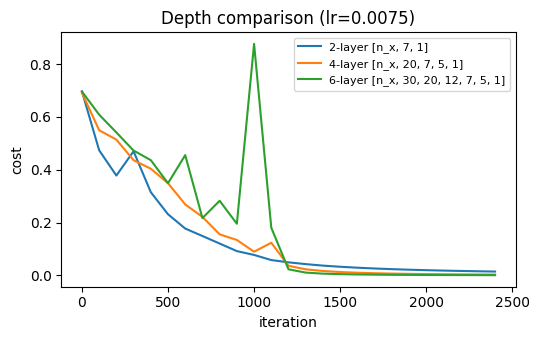

In [ ]:
configs = {
    "2-layer [n_x, 7, 1]": [n_x, 7, 1],
    "4-layer [n_x, 20, 7, 5, 1]": [n_x, 20, 7, 5, 1],
    "6-layer [n_x, 30, 20, 12, 7, 5, 1]": [n_x, 30, 20, 12, 7, 5, 1],
}
models = {}
for name, dims in configs.items():
    net = DeepNetwork(dims, learning_rate=0.0075, num_iterations=2500, init="he").fit(X_train, y_train)
    models[name] = net
    print(f"{name:<28} train={net.score(X_train, y_train):.1%}  test={net.score(X_test, y_test):.1%}")

plt.figure(figsize=(5.5, 3.5))
for name, net in models.items():
    plt.plot(np.arange(len(net.costs_)) * net.log_every, net.costs_, label=name)
plt.xlabel("iteration")
plt.ylabel("cost")
plt.legend(fontsize=8)
plt.title("Depth comparison (lr=0.0075)")
plt.tight_layout()
plt.savefig(ASSETS / "depth_comparison.png", dpi=150)
plt.show()

## 3. Initialization: N(0, 0.01^2) vs He (6-layer network)

init=small  final cost=0.6440  train=65.6%  test=34.0%
init=he     final cost=0.0013  train=100.0%  test=76.0%


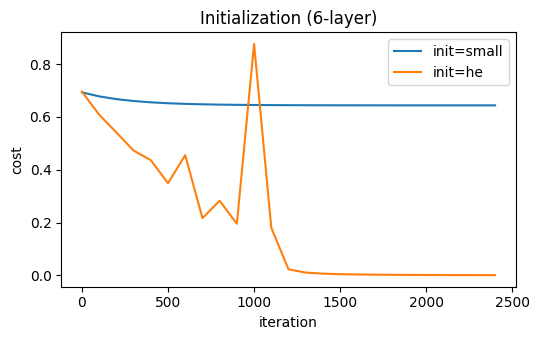

In [ ]:
dims = configs["6-layer [n_x, 30, 20, 12, 7, 5, 1]"]
init_runs = {}
for init in ["small", "he"]:
    net = DeepNetwork(dims, learning_rate=0.0075, num_iterations=2500, init=init).fit(X_train, y_train)
    init_runs[init] = net
    print(f"init={init:<6} final cost={net.costs_[-1]:.4f}  train={net.score(X_train, y_train):.1%}  test={net.score(X_test, y_test):.1%}")

plt.figure(figsize=(5.5, 3.5))
for init, net in init_runs.items():
    plt.plot(np.arange(len(net.costs_)) * net.log_every, net.costs_, label=f"init={init}")
plt.xlabel("iteration")
plt.ylabel("cost")
plt.legend()
plt.title("Initialization (6-layer)")
plt.tight_layout()
plt.savefig(ASSETS / "init_comparison.png", dpi=150)
plt.show()

## 4. Error analysis (6-layer, He init)

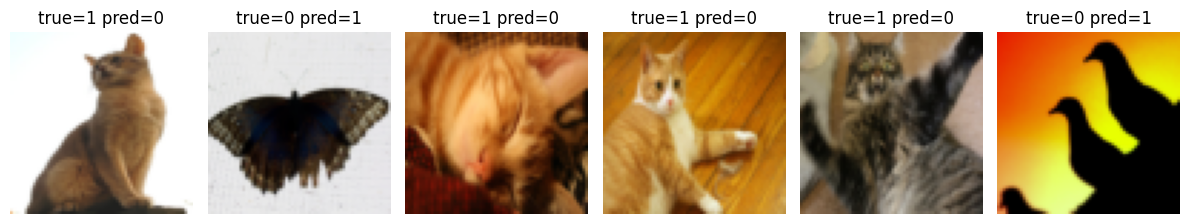

In [37]:
best = init_runs["he"]
pred = best.predict(X_test)
wrong = np.where(pred[0] != y_test[0])[0][:6]
fig, axes = plt.subplots(1, max(len(wrong), 1), figsize=(12, 2.4))
for ax, i in zip(np.atleast_1d(axes), wrong):
    ax.imshow(x_test_img[i])
    ax.set_title(f"true={int(y_test[0, i])} pred={int(pred[0, i])}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(ASSETS / "misclassified.png", dpi=150)
plt.show()

## 5. Results and notes

- **2-layer vs 4-layer vs 6-layer, train/test accuracy:**
All three configurations reach train accuracy 100% (perfect memorization),
while test accuracy grows with depth: 72% → 74% → 76% (+2 pp per +2 layers).
The gain comes from higher expressive capacity: deeper layers build more
complex non-linear decision boundaries that better separate cat-specific
features (fur texture, ear shape, whiskers). 
The 6-layer cost curve shows a visible spike around
 iteration ~1000 — a sign of training instability (gradient explosion).

- **Effect of initialization on the cost curve:**
`init=small` (std=0.01) suffers from vanishing gradients: signal variance
shrinks exponentially through layers, so weights barely update — cost plateaus
at 0.64 and the model stays at chance level (test 34%). `init=he` (std=√(2/n_in))
preserves signal variance across layers, cost drops to 0.0013, and the model
reaches 76% test. 
Conclusion: initialization directly determines whether
signal/gradients survive propagation through depth — for ReLU networks
He-init is the correct choice.

- **Train/test gap and why (compare with logistic regression and the shallow network):**
All models hit 100% on train but only 72–76% on test — a 24–28 pp gap,
i.e. heavy overfitting. The training set contains only 209 images, so
any network with tens of thousands of parameters is essentially memorizing.
Logistic regression and the 2-layer net land at similar test accuracy,
while the 6-layer net adds only ~4 pp at a much higher parameter/compute cost.
Conclusion: for this dataset, depth is weakly justified; the bottleneck is
data, not model capacity. Regularization or a larger dataset would probably 
help more than adding layers.

- **Typical errors:**
Misclassified examples show that the network learned low-level correlations
(fur texture, ear shape, symmetric "eye" spots) rather than the semantic
concept of a cat. It confuses cats with fluffy animals and, conversely,
predicts "cat" for butterflies whose wing patterns resemble cat faces.
This is the classic signature of overfitting on small data:
the model latches onto spurious correlations that hold in the training set
but do not generalize.